In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv(r"D:\anshs\Project 1new\data\exam_marks.csv")


In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group D,some college,standard,completed,59,70,78
1,male,group D,associate's degree,standard,none,96,93,87
2,female,group D,some college,free/reduced,none,57,76,77
3,male,group B,some college,free/reduced,none,70,70,63
4,female,group D,associate's degree,standard,none,83,85,86


In [4]:
df.shape

(1000, 8)

In [5]:

df.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [6]:
df.duplicated().sum()


np.int64(0)

In [7]:
# Check Null and Dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [8]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     79
reading score                  71
writing score                  74
dtype: int64

In [9]:
df.describe()

,math score,reading score,writing score
count,1000.000000,1000.000000,1000.000000
mean,67.810000,70.382000,69.140000
std,15.250196,14.107413,15.025917
min,15.000000,25.000000,15.000000
25%,58.000000,61.000000,59.000000
50%,68.000000,70.500000,70.000000
75%,79.250000,80.000000,80.000000
max,100.000000,100.000000,100.000000


In [10]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group D,some college,standard,completed,59,70,78
1,male,group D,associate's degree,standard,none,96,93,87
2,female,group D,some college,free/reduced,none,57,76,77
3,male,group B,some college,free/reduced,none,70,70,63
4,female,group D,associate's degree,standard,none,83,85,86


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [12]:
print("categories in 'gender' variable:    ",end = " ")
print(df['gender'].unique())

print("categories in 'race/ethnicity' variable:    ",end = " ")
print(df['race/ethnicity'].unique())

print("categories in parental level of education' variable:    ",end = " ")
print(df['parental level of education'].unique())

print("categories in 'race/ethnicity' variable:    ",end = " ")
print(df['lunch'].unique())

print("categories in 'test preparation course' variable:    ",end = " ")
print(df['test preparation course'].unique())

categories in 'gender' variable:     <StringArray>
['female', 'male']
Length: 2, dtype: str
categories in 'race/ethnicity' variable:     <StringArray>
['group D', 'group B', 'group C', 'group E', 'group A']
Length: 5, dtype: str
categories in parental level of education' variable:     <StringArray>
[      'some college', 'associate's degree',   'some high school',
  'bachelor's degree',    'master's degree',        'high school']
Length: 6, dtype: str
categories in 'race/ethnicity' variable:     <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
categories in 'test preparation course' variable:     <StringArray>
['completed', 'none']
Length: 2, dtype: str


In [13]:
# define numerical & categorical columns
numeric_features = [feature for feature in df.columns if df[feature].dtype !='str']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'str']

# print columns
print("We have {} numerical features : {}".format(len(numeric_features),numeric_features))
print("We have {} categorical features : {}".format(len(categorical_features),categorical_features))

We have 3 numerical features : ['math score', 'reading score', 'writing score']
We have 5 categorical features : ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [14]:
df.head(2)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group D,some college,standard,completed,59,70,78
1,male,group D,associate's degree,standard,none,96,93,87


In [15]:
df['total_score'] = df['math score'] + df['reading score'] + df['writing score']
df['average'] = df['total_score']/3
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average
0,female,group D,some college,standard,completed,59,70,78,207,69.000000
1,male,group D,associate's degree,standard,none,96,93,87,276,92.000000
2,female,group D,some college,free/reduced,none,57,76,77,210,70.000000
3,male,group B,some college,free/reduced,none,70,70,63,203,67.666667
4,female,group D,associate's degree,standard,none,83,85,86,254,84.666667


In [16]:
reading_full = df[df['reading score'] == 100]['average'].count()
writing_full = df[df['writing score'] == 100]['average'].count()
math_full = df[df['math score'] == 100]['average'].count()

print(f"Number of students with full marks in maths: {math_full}")
print(f"Number of students with full marks in writing: {writing_full}")
print(f"Number of students with full marks in reading: {reading_full}")

Number of students with full marks in maths: 9
Number of students with full marks in writing: 13
Number of students with full marks in reading: 10


In [17]:
reading_less_20 = df[df['reading score'] <= 20]['average'].count()
writing_less_20 = df[df['writing score'] <= 20]['average'].count()
math_less_20 = df[df['math score'] <= 20]['average'].count()

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')


Number of students with less than 20 marks in Maths: 2
Number of students with less than 20 marks in Writing: 2
Number of students with less than 20 marks in Reading: 0


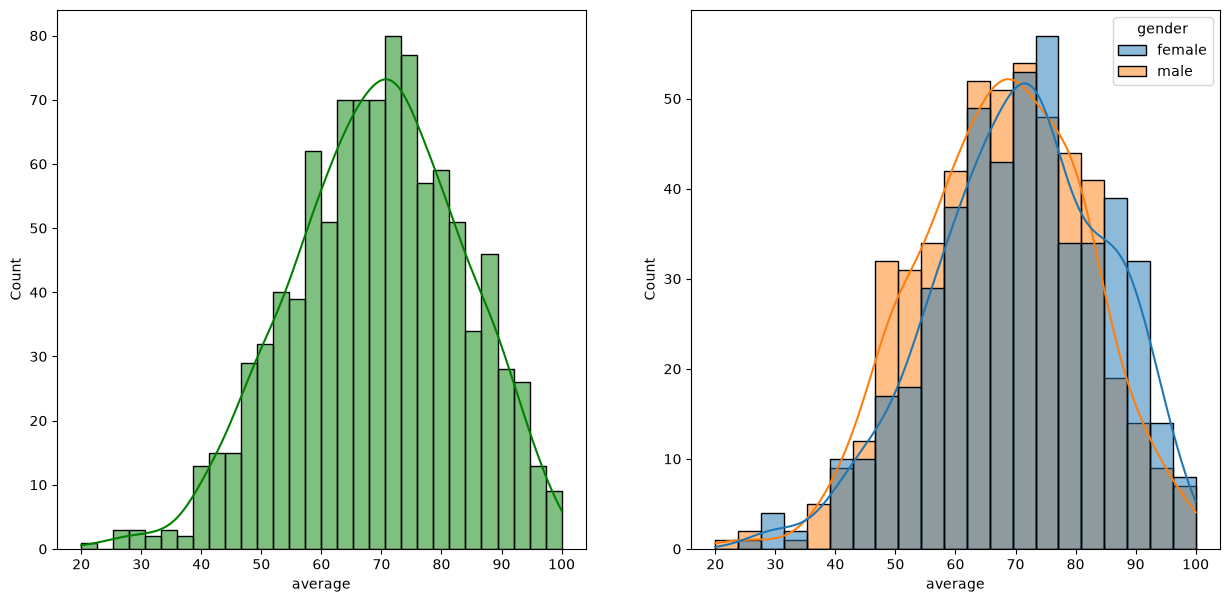

In [18]:
fig, axs = plt.subplots(1, 2, figsize = (15, 7))
plt.subplot(121)
sns.histplot(data = df, x = 'average', bins = 30, kde = True, color = 'g')
plt.subplot(122)
sns.histplot(data = df, x = 'average', kde = True, hue = 'gender')
plt.show()

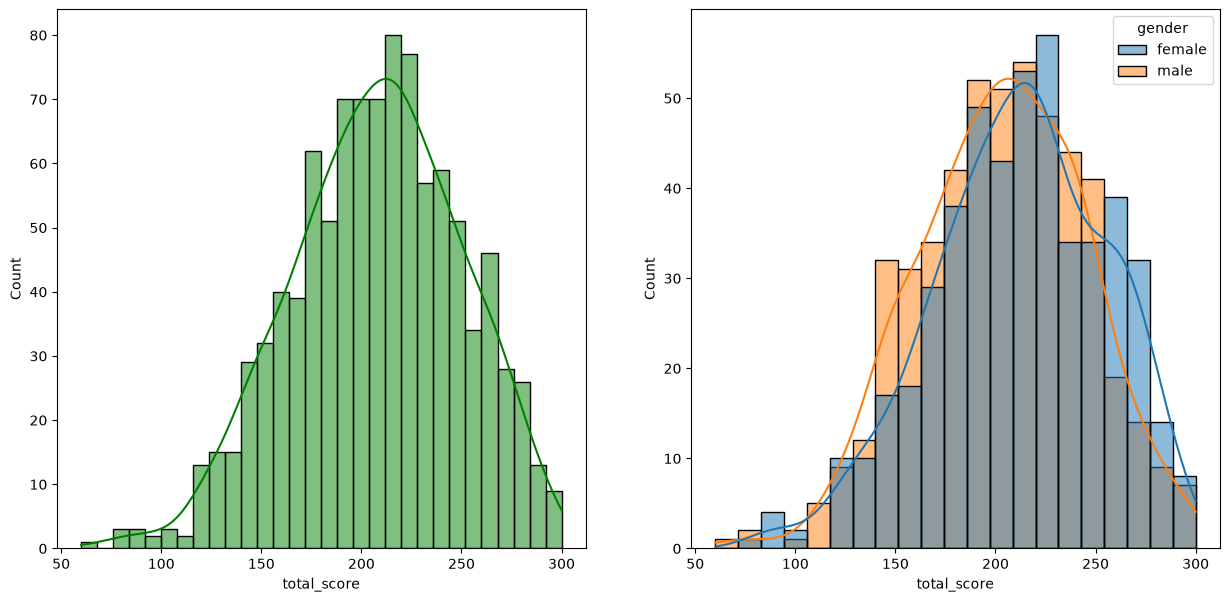

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df,x='total_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total_score',kde=True,hue='gender')
plt.show()

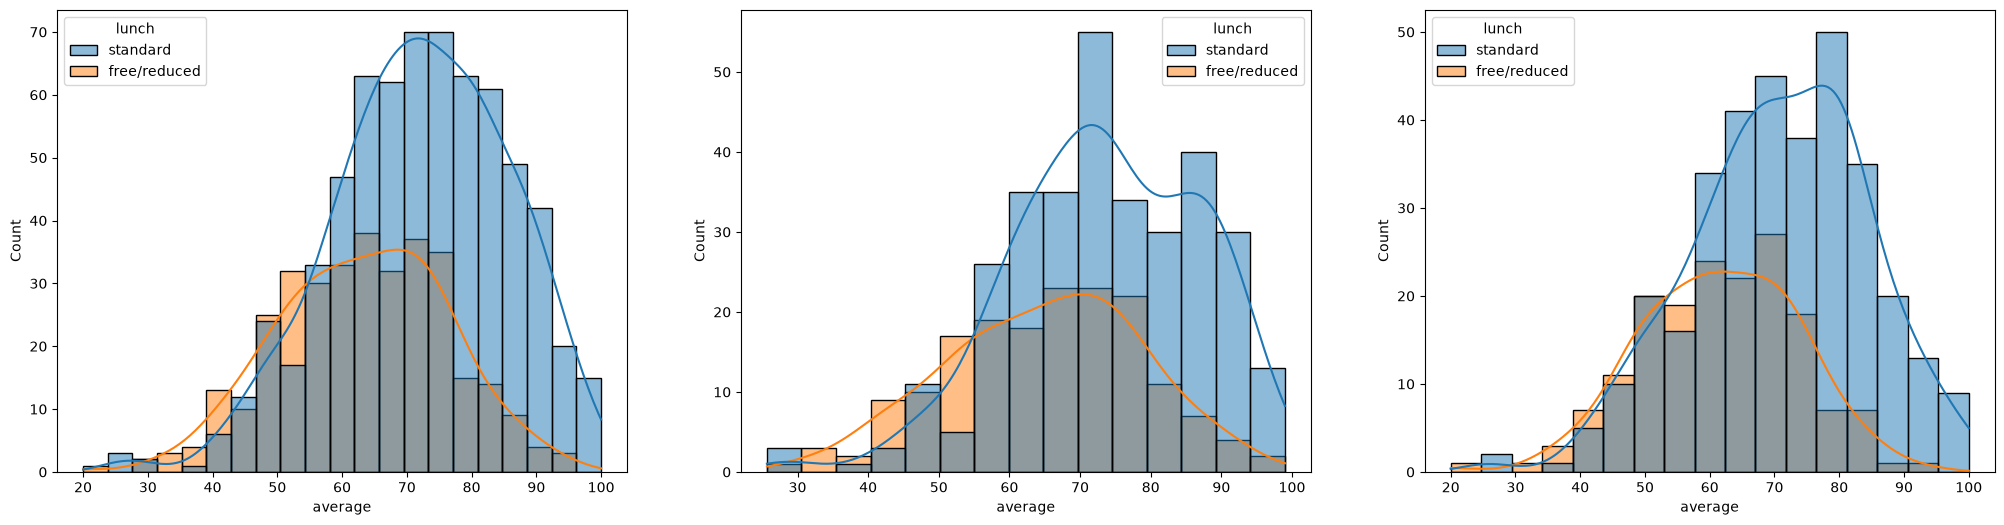

In [20]:
plt.subplots(1, 3, figsize = (25,6))
plt.subplot(131)
sns.histplot(data = df,x = 'average',kde = True, hue = 'lunch')
plt.subplot(132)
sns.histplot(data = df[df.gender == 'female'], x = 'average', kde = True, hue = 'lunch')
plt.subplot(133)
sns.histplot(data = df[df.gender == 'male'], x = 'average', kde = True, hue = 'lunch')
plt.show()

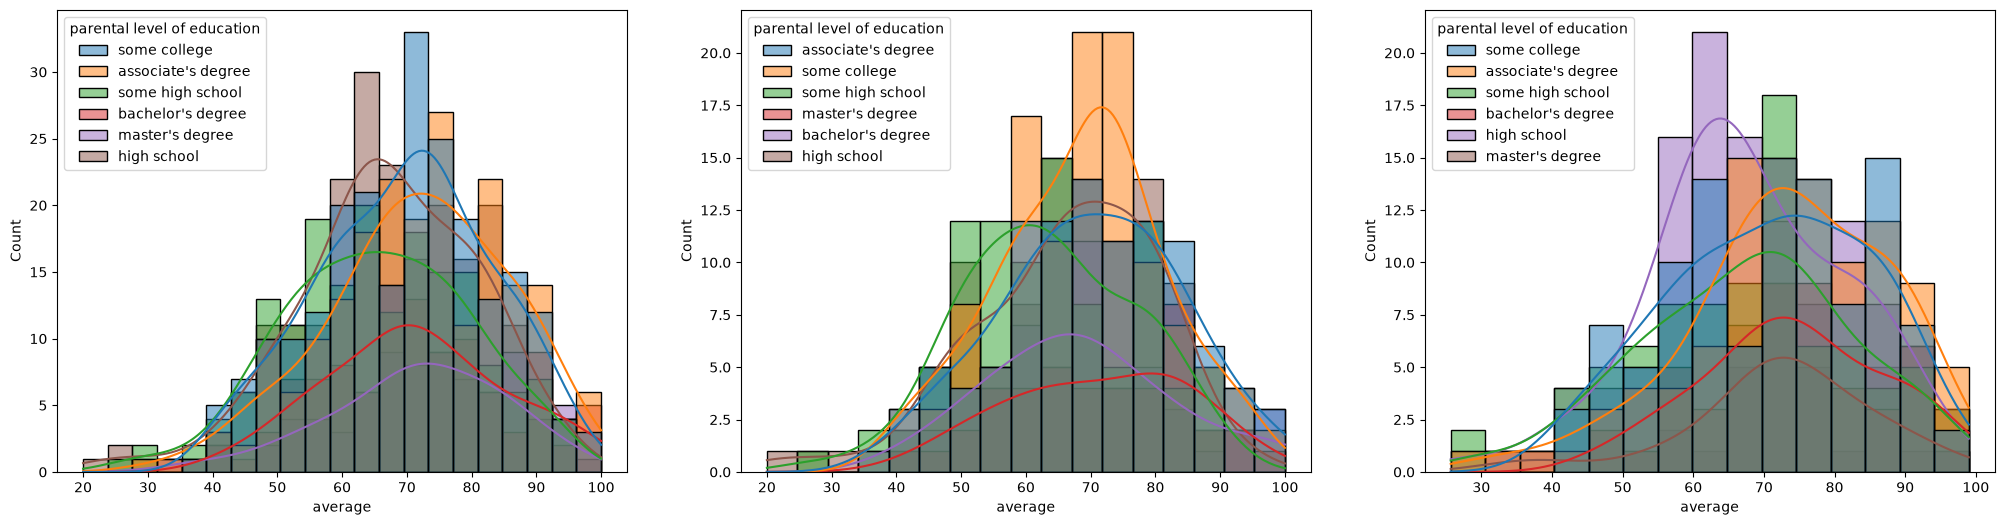

In [21]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131)
ax =sns.histplot(data=df,x='average',kde=True,hue='parental level of education')
plt.subplot(132)
ax =sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='parental level of education')
plt.subplot(133)
ax =sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='parental level of education')
plt.show()

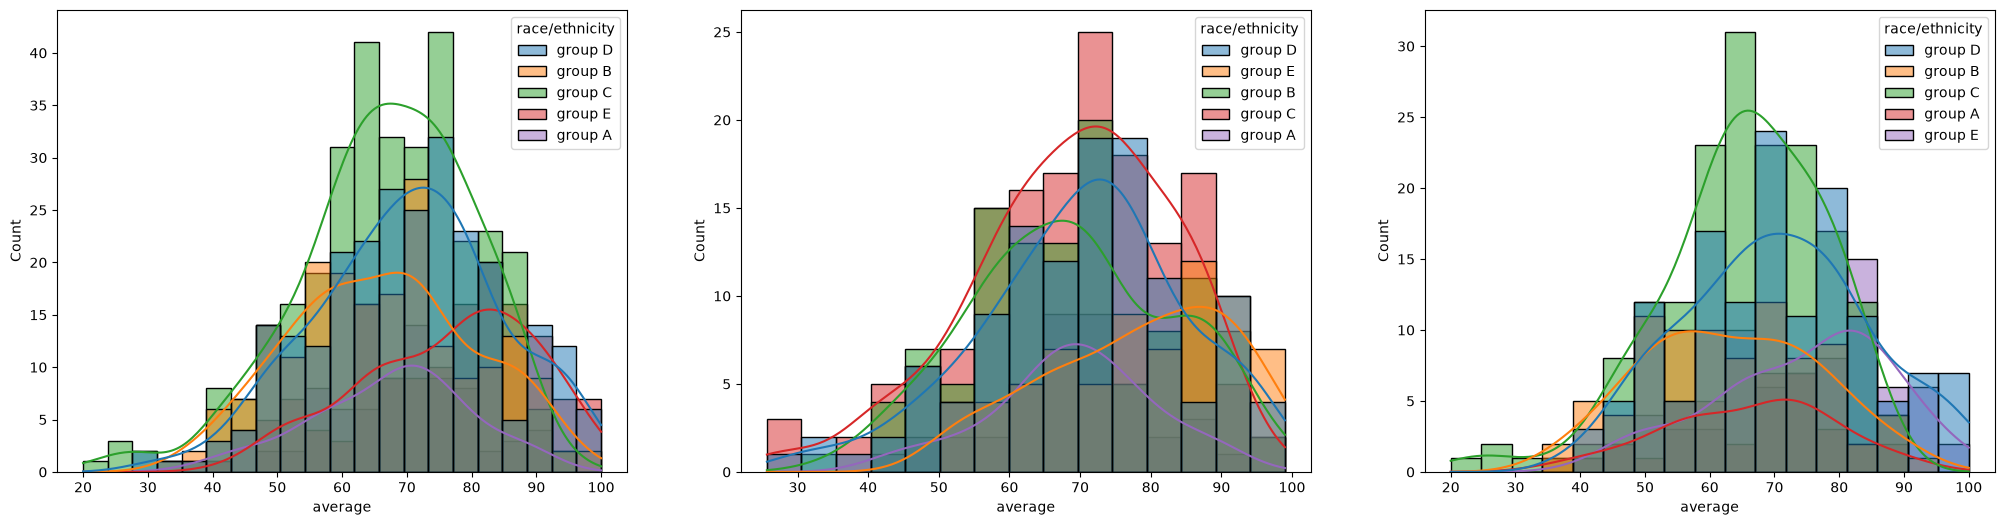

In [22]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131)
ax =sns.histplot(data=df,x='average',kde=True,hue='race/ethnicity')
plt.subplot(132)
ax =sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='race/ethnicity')
plt.subplot(133)
ax =sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='race/ethnicity')
plt.show()


In [23]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average
0,female,group D,some college,standard,completed,59,70,78,207,69.000000
1,male,group D,associate's degree,standard,none,96,93,87,276,92.000000
2,female,group D,some college,free/reduced,none,57,76,77,210,70.000000
3,male,group B,some college,free/reduced,none,70,70,63,203,67.666667
4,female,group D,associate's degree,standard,none,83,85,86,254,84.666667


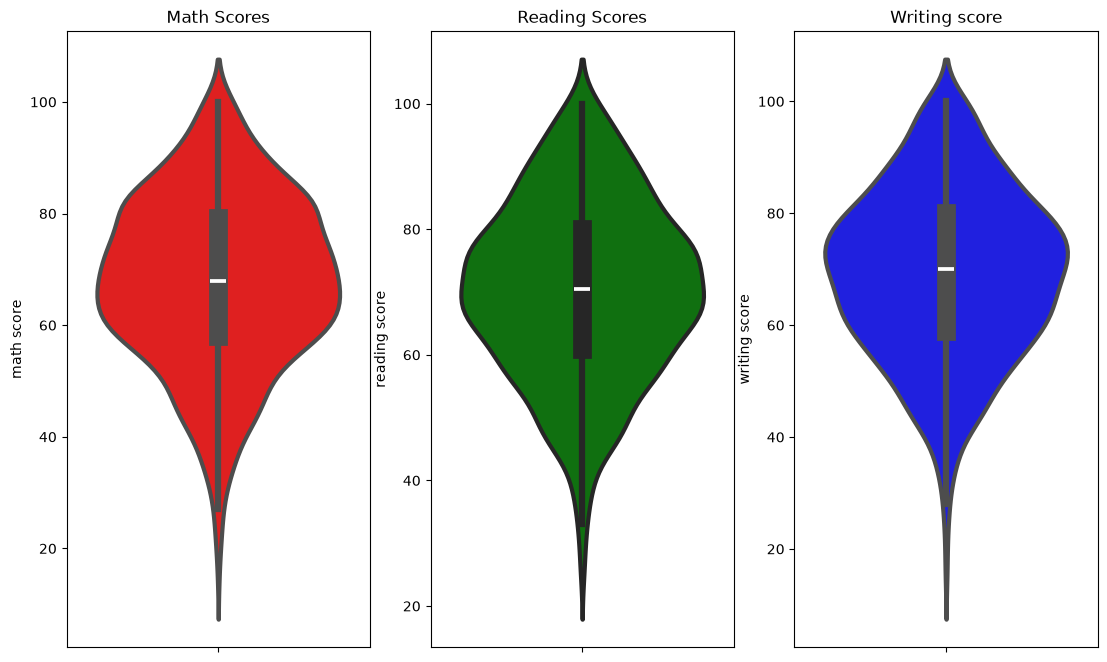

In [24]:
plt.figure(figsize = (18,8))
plt.subplot(1,4,1)
plt.title("Math Scores")
sns.violinplot(y = "math score", data = df, color = 'red', linewidth = 3)
plt.subplot(1,4,2)
plt.title("Reading Scores")
sns.violinplot(y = "reading score", data = df, color = 'green',linewidth = 3)
plt.subplot(1, 4, 3)
plt.title("Writing score")
sns.violinplot(y = "writing score", data = df, color = 'blue', linewidth = 3)
plt.show()

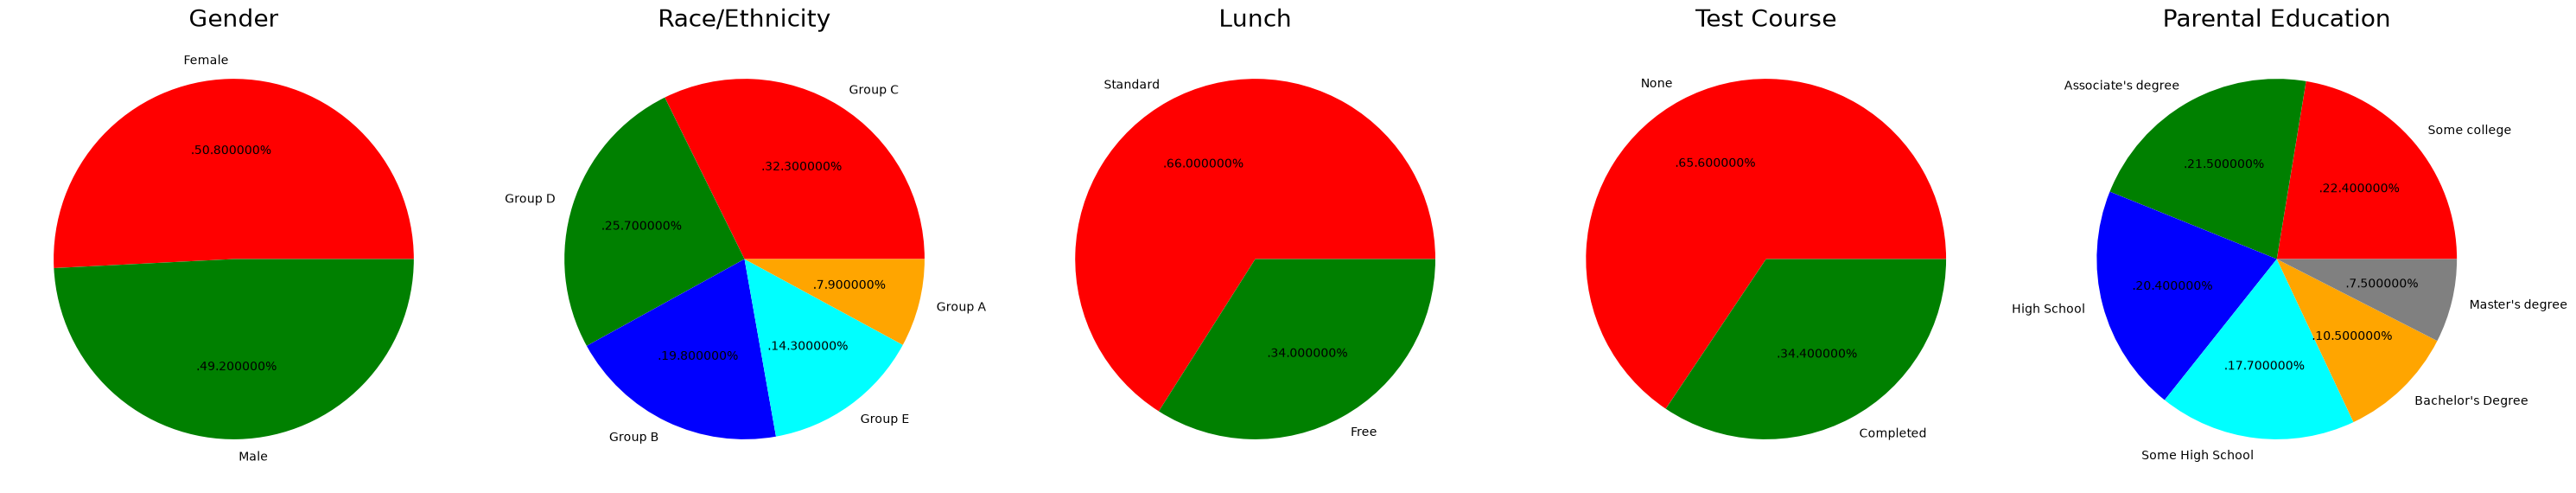

In [25]:
plt.rcParams['figure.figsize'] = (30,12)

plt.subplot(1, 5, 1)
size = df['gender'].value_counts()
labels = 'Female', 'Male'
color = ['red', 'green']

plt.pie(size, colors = color, labels = labels, autopct = '.%2f%%')
plt.title('Gender', fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 2)
size = df['race/ethnicity'].value_counts()
labels = 'Group C','Group D', 'Group B', 'Group E', 'Group A'
color = ['red', 'green', 'blue', 'cyan', 'orange']

plt.pie(size, colors = color, labels = labels, autopct = '.%2f%%')
plt.title('Race/Ethnicity', fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 3)
size = df['lunch'].value_counts()
labels = 'Standard', 'Free'
color = ['red', 'green']

plt.pie(size, colors = color, labels = labels, autopct = '.%2f%%')
plt.title("Lunch", fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 4)
size = df['test preparation course'].value_counts()
labels = 'None', 'Completed'
color = ['red', 'green']

plt.pie(size, colors = color, labels = labels, autopct = '.%2f%%')
plt.title("Test Course", fontsize = 20)
plt.axis('off')

plt.subplot(1, 5, 5)
size = df['parental level of education'].value_counts()
labels = 'Some college', "Associate's degree","High School", "Some High School", "Bachelor's Degree", "Master's degree"
color = ['red', 'green', 'blue', 'cyan', 'orange', 'grey']

plt.pie(size, colors = color, labels = labels, autopct = '.%2f%%')
plt.title('Parental Education', fontsize = 20)
plt.axis('off')
plt.tight_layout()
plt.grid()

plt.show()

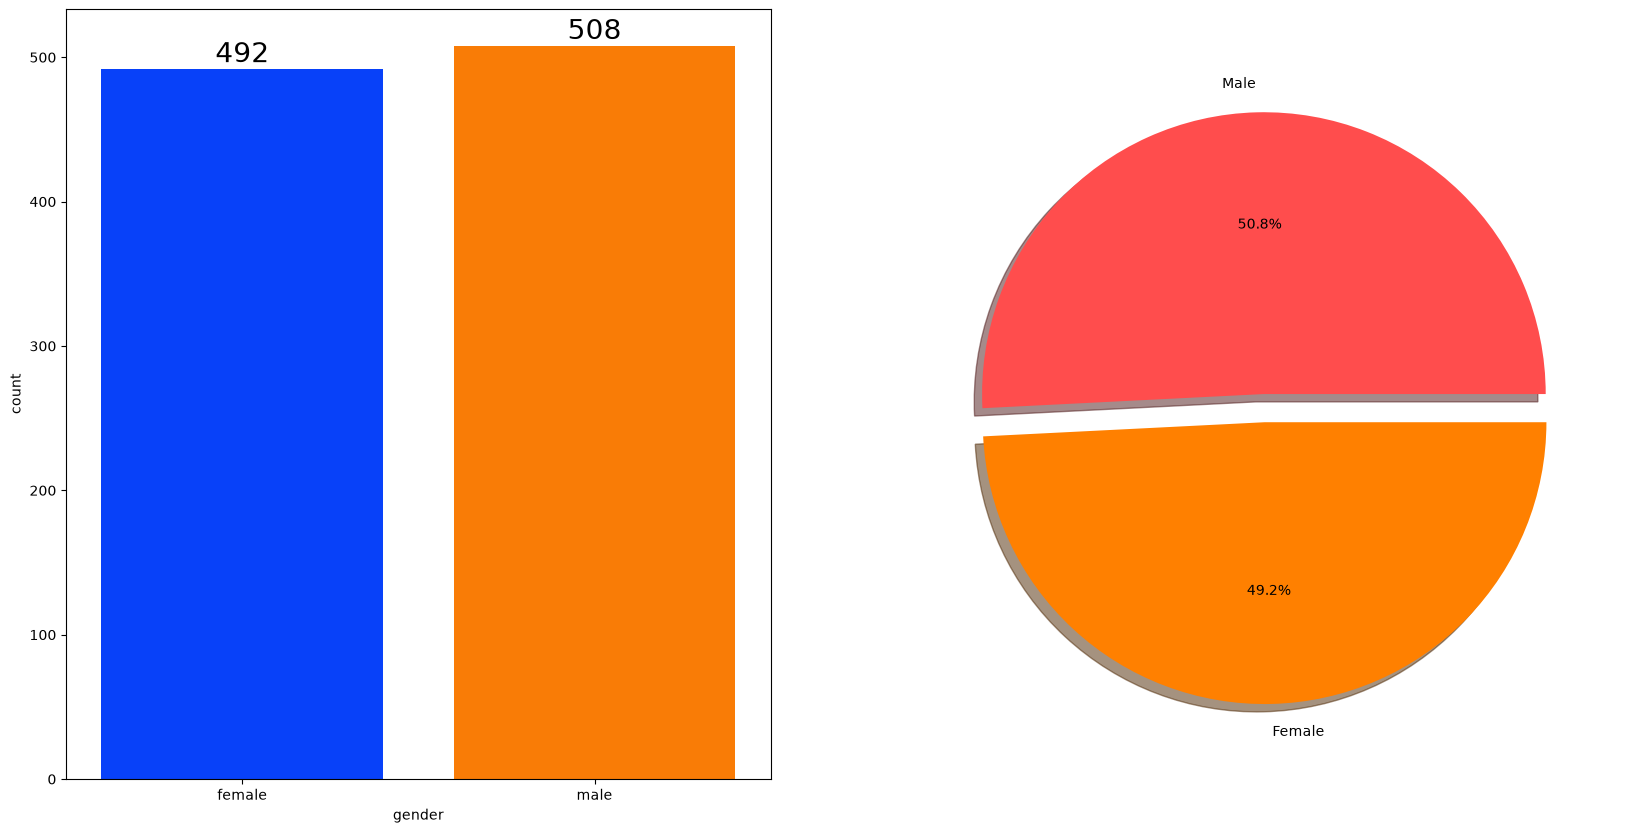

In [26]:
f, ax = plt.subplots(1, 2, figsize = (20, 10))
sns.countplot(x = df['gender'], data = df, palette = 'bright', ax = ax[0], saturation = 0.95)
for container in ax[0].containers:
    ax[0].bar_label(container, color = 'black', size = 20)
plt.pie(x = df['gender'].value_counts(), labels = ['Male', 'Female'], explode = [0, 0.1], autopct = '%1.1f%%', shadow = True, colors = ['#ff4d4d', '#ff8000'])
plt.show()

In [27]:
gender_group = df.groupby('gender').mean(numeric_only=True)
gender_group

,math score,reading score,writing score,total_score,average
gender,,,,,
female,64.77439,73.473577,73.439024,211.686992,70.562331
male,70.75000,67.387795,64.976378,203.114173,67.704724


In [28]:
gender_group['average']['female']

np.float64(70.56233062330622)

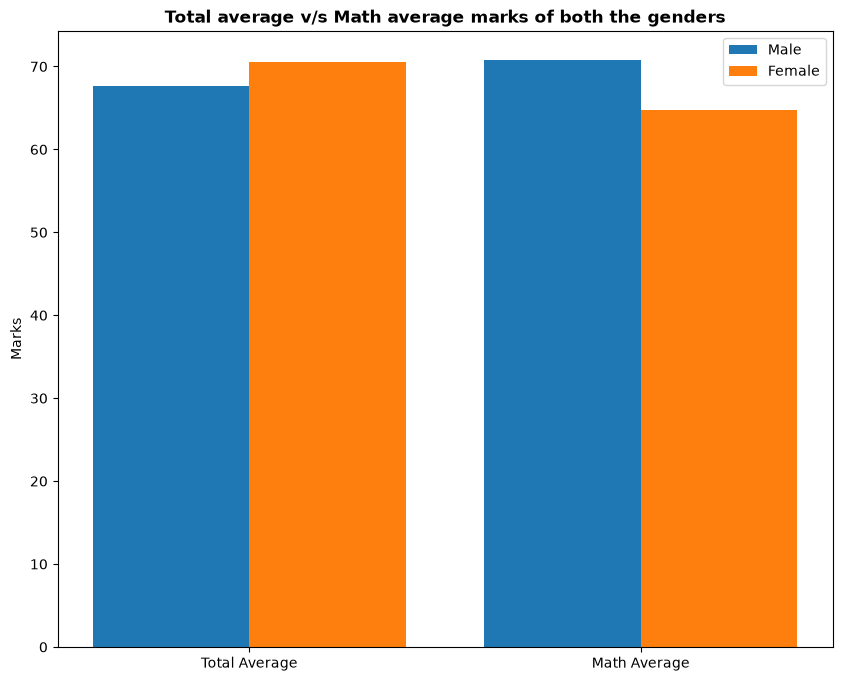

In [29]:
plt.figure(figsize =(10, 8))

X = ['Total Average', 'Math Average']

female_scores = [gender_group['average']['female'], gender_group['math score']['female']]
male_scores = [gender_group['average']['male'], gender_group['math score']['male']]

X_axis = np.arange(len(X))

plt.bar(X_axis - 0.2, male_scores, 0.4, label = 'Male')
plt.bar(X_axis + 0.2, female_scores, 0.4, label = 'Female')

plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight = 'bold')
plt.legend()
plt.show()

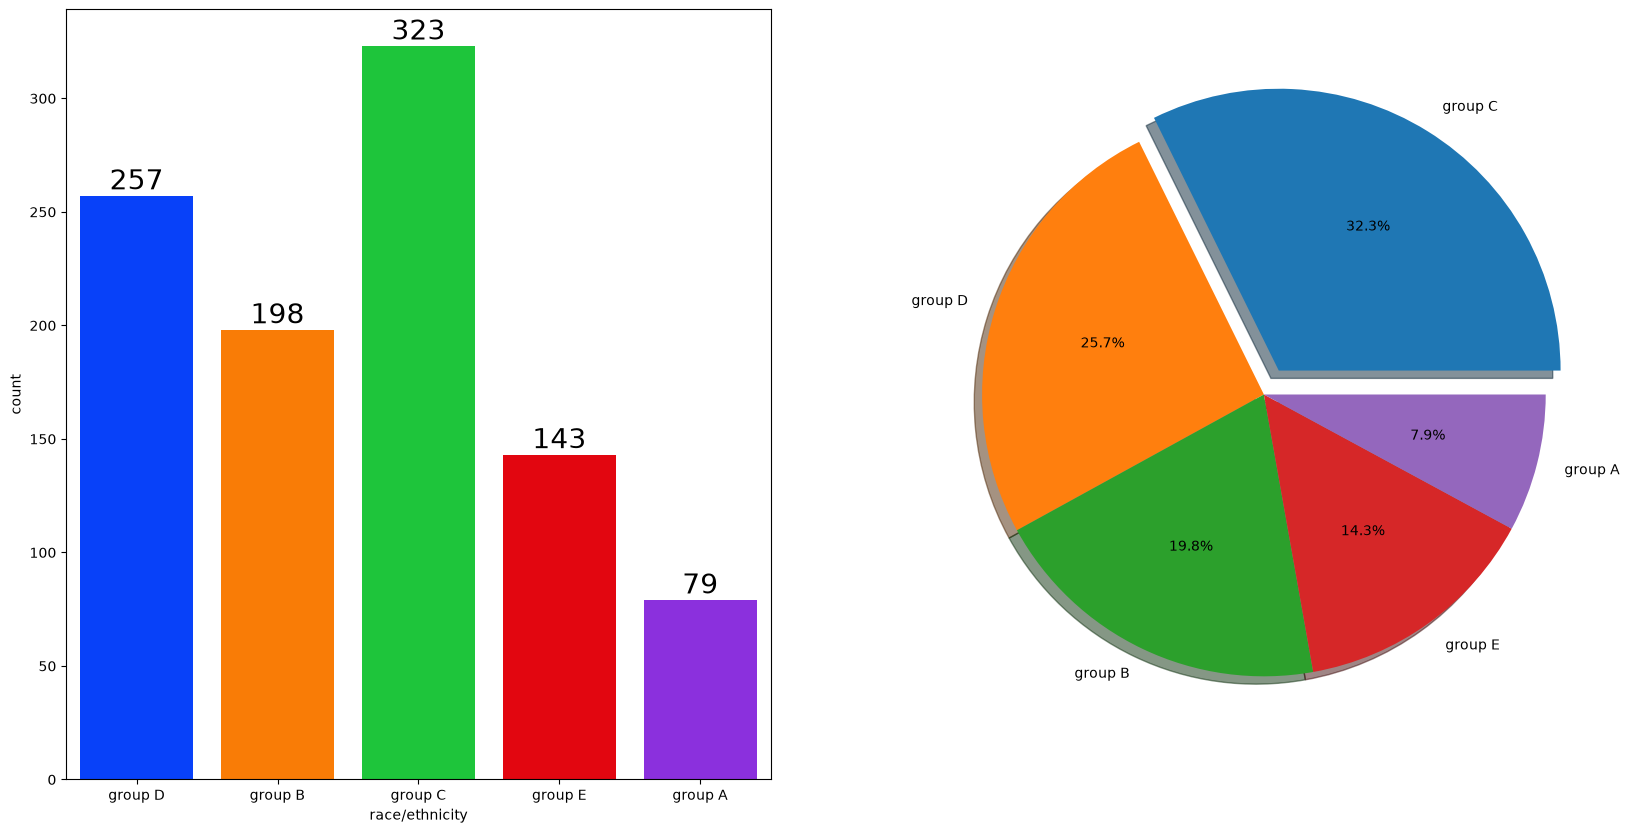

In [30]:
f, ax = plt.subplots(1, 2, figsize = (20, 10))
sns.countplot(x = df['race/ethnicity'], data = df, palette = 'bright', ax = ax[0], saturation = 0.95)
for container in ax[0].containers:
    ax[0].bar_label(container, color = 'black', size = 20)


plt.pie(x = df['race/ethnicity'].value_counts(), labels = df['race/ethnicity'].value_counts().index, explode = [0.1, 0, 0, 0, 0], autopct = '%1.1f%%', shadow = True)
plt.show()

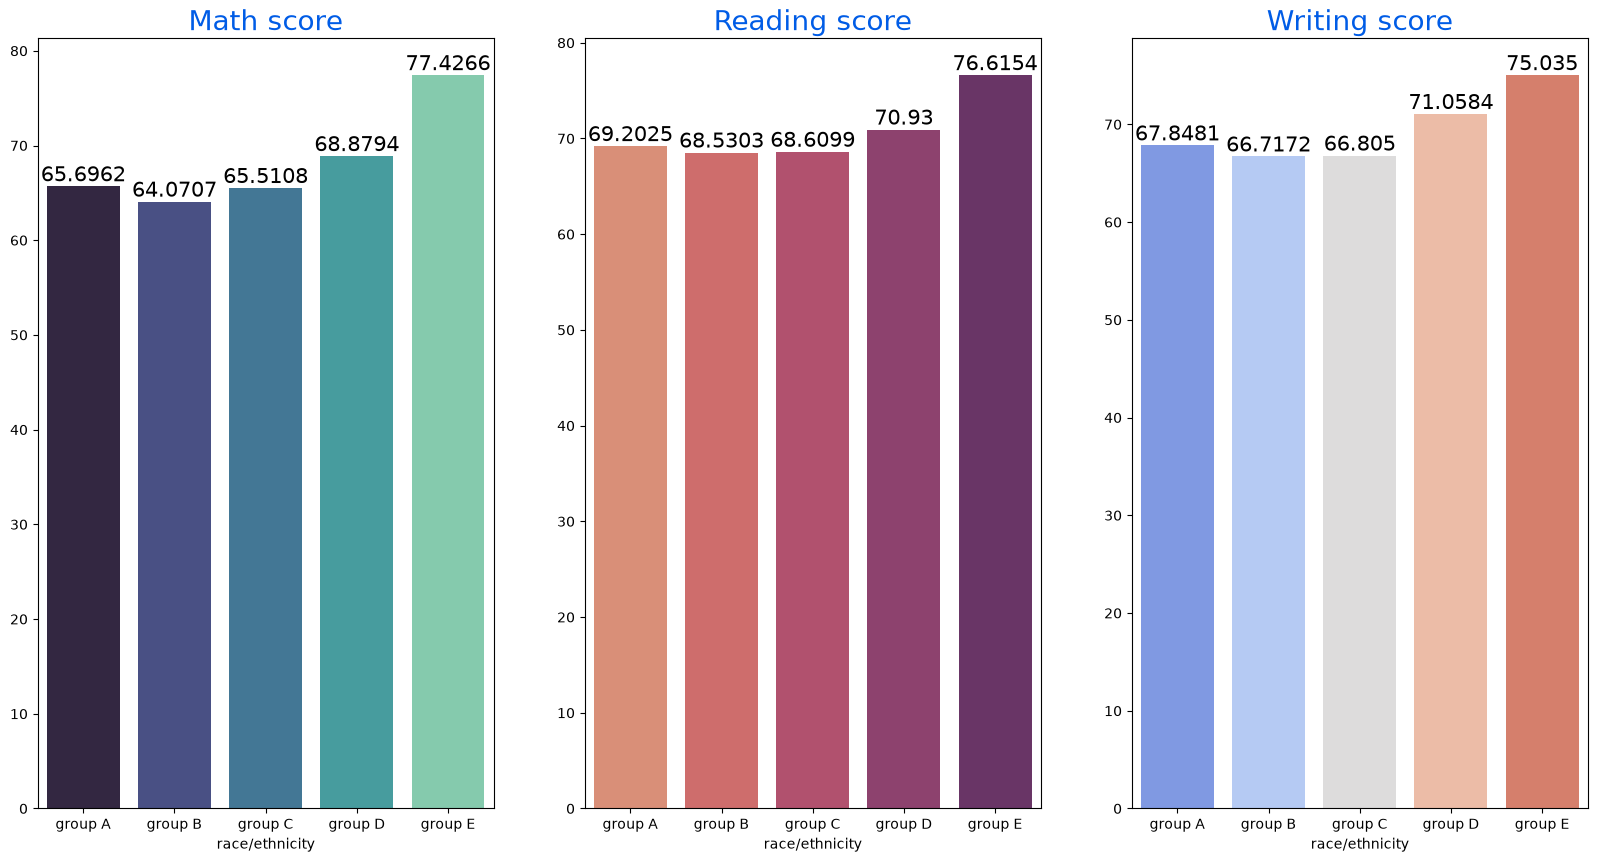

In [31]:
group_data2 = df.groupby('race/ethnicity')
f, ax = plt.subplots(1, 3, figsize = (20, 10))
sns.barplot(x = group_data2['math score'].mean().index, y = group_data2['math score'].mean().values, palette = 'mako', ax = ax[0])
ax[0].set_title('Math score', color = '#005ce6', size = 20)

for container in ax[0].containers:
    ax[0].bar_label(container, color = 'black', size = 15)

sns.barplot(x = group_data2['reading score'].mean().index, y = group_data2['reading score'].mean().values, palette = 'flare', ax = ax[1])
ax[1].set_title('Reading score', color = '#005ce6', size = 20)

for container in ax[1].containers:
    ax[1].bar_label(container, color = 'black', size = 15)

sns.barplot(x = group_data2['writing score'].mean().index, y = group_data2['writing score'].mean().values, palette = 'coolwarm', ax = ax[2])
ax[2].set_title('Writing score', color = '#005ce6', size = 20)

for container in ax[2].containers:
    ax[2].bar_label(container, color = 'black', size = 15)

findfont: Failed to find font weight 30 for DejaVu Sans, now using 400.


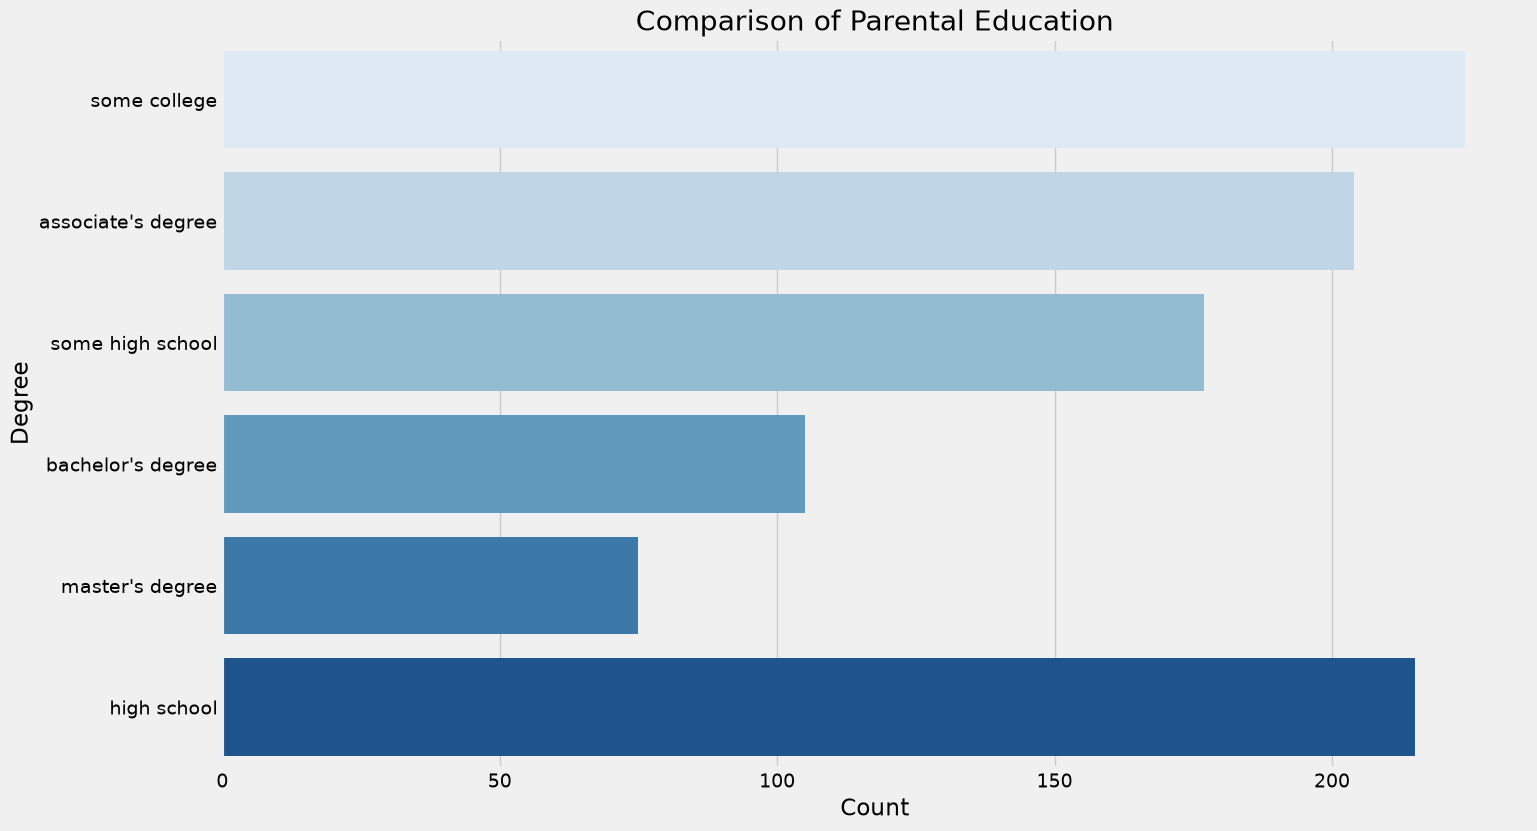

In [32]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('fivethirtyeight')
sns.countplot(df['parental level of education'], palette = 'Blues')
plt.title('Comparison of Parental Education', fontweight = 30, fontsize = 20)
plt.xlabel('Count')
plt.ylabel('Degree')
plt.show()

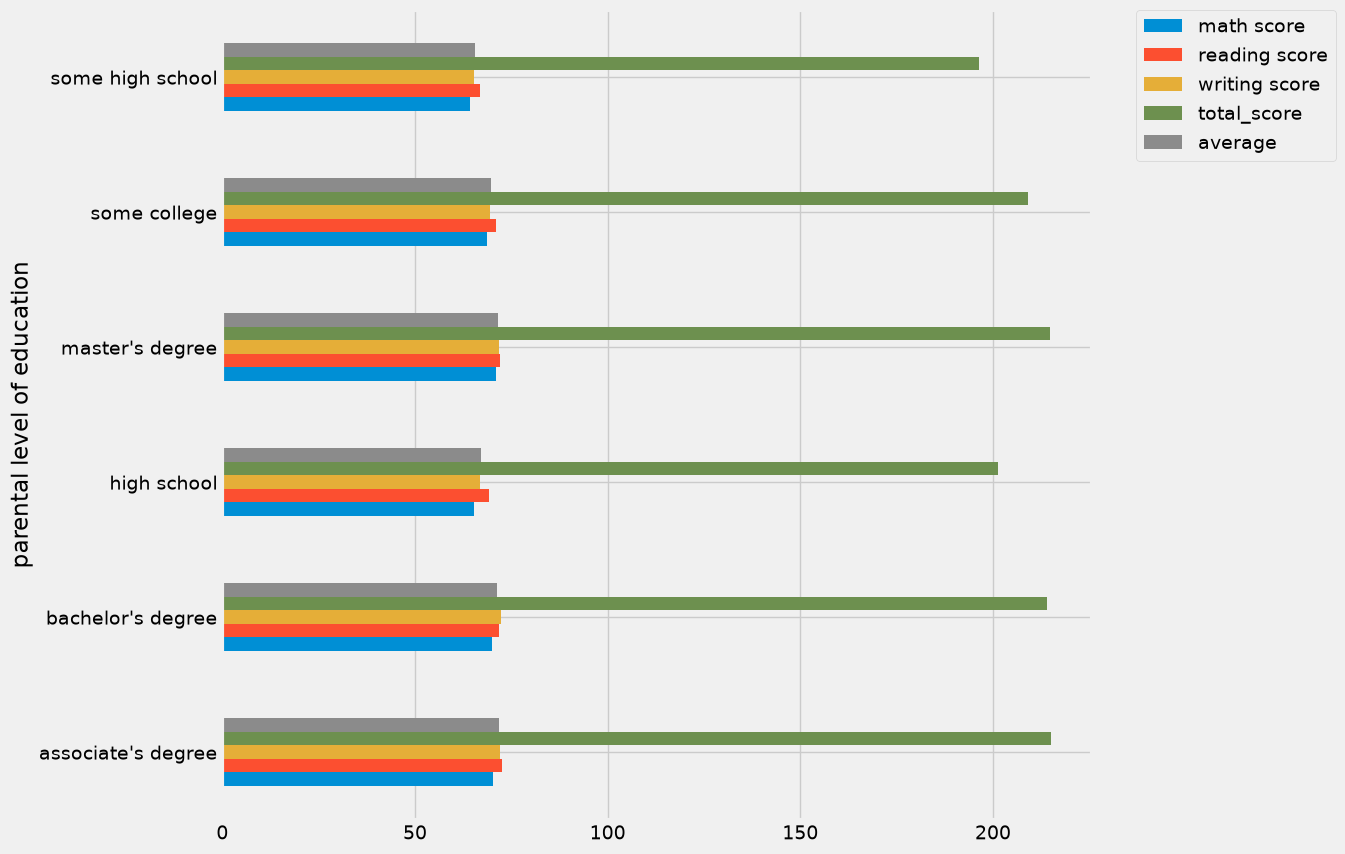

In [33]:
df.groupby('parental level of education').mean(numeric_only=True).plot(kind = 'barh', figsize = (10, 10))
plt.legend(bbox_to_anchor = (1.05, 1), loc = 2, borderaxespad = 0.)
plt.show()

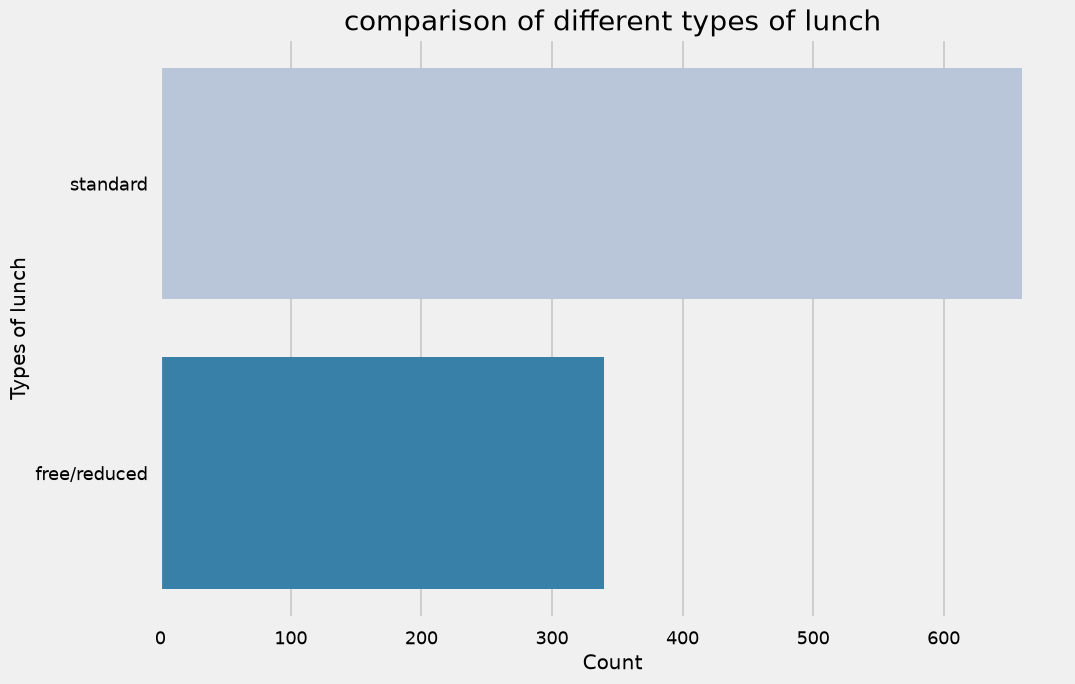

In [34]:
plt.rcParams['figure.figsize'] = (15, 9)
plt.style.use('seaborn-v0_8-talk')
sns.countplot(df['lunch'], palette = 'PuBu')
plt.title('comparison of different types of lunch', fontweight = 30, fontsize = 20)
plt.xlabel('Count')
plt.ylabel('Types of lunch')
plt.show()

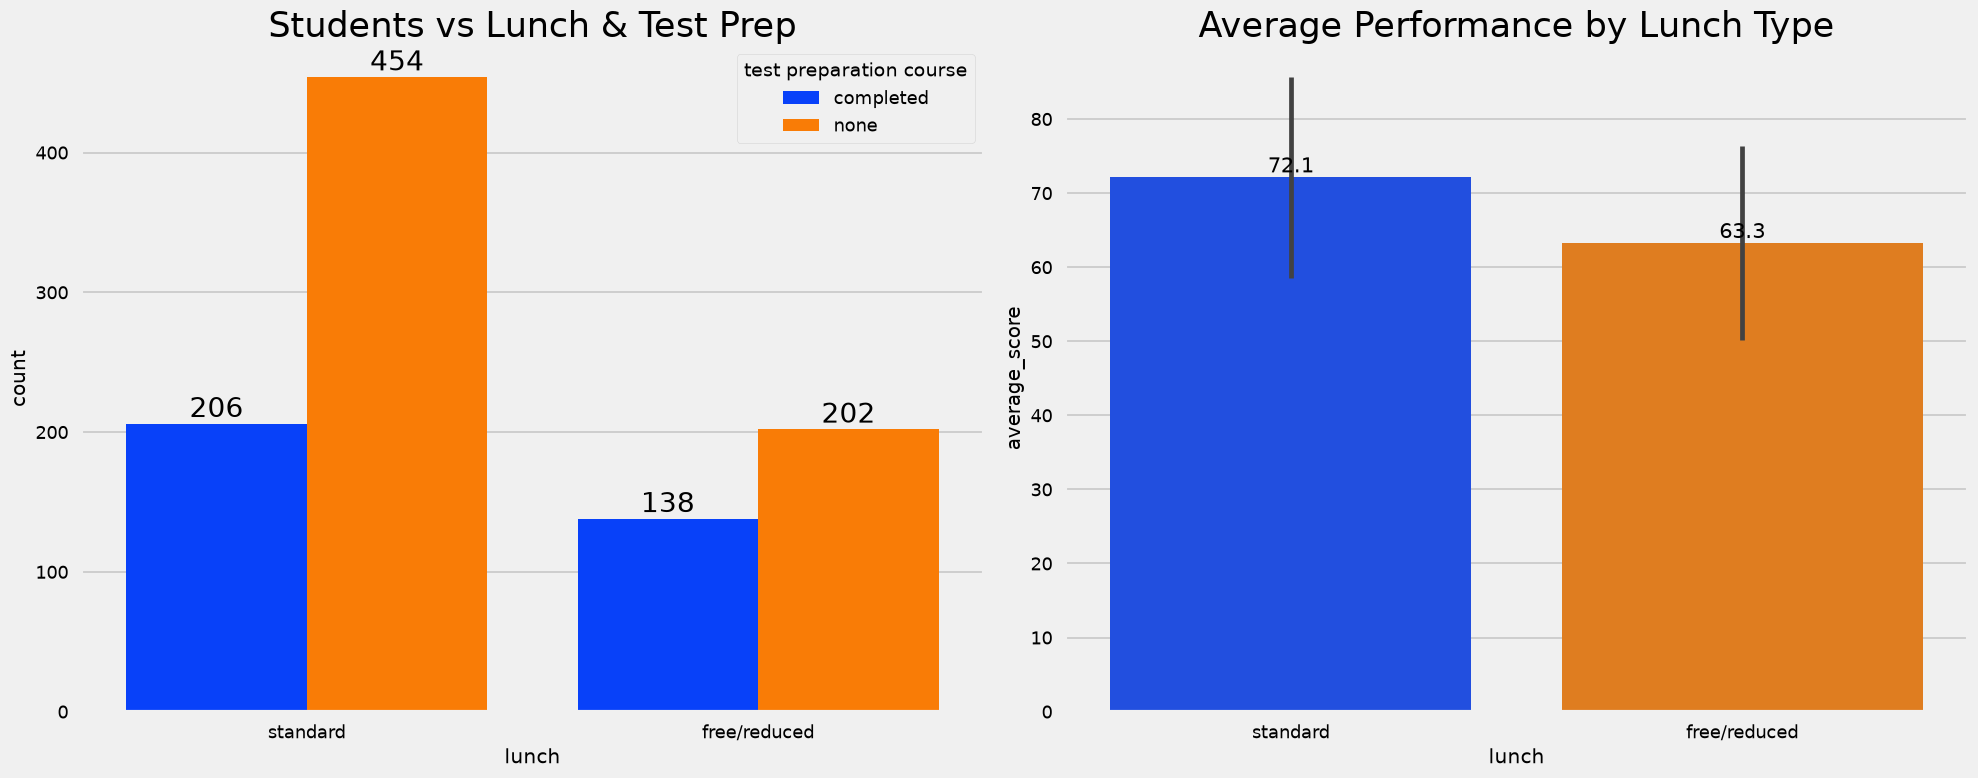

In [35]:
f, ax = plt.subplots(1, 2, figsize=(20, 8))

# Plot 1: Lunch type vs test preparation course
sns.countplot(x='lunch', data=df, palette='bright', hue='test preparation course', saturation=0.95, ax=ax[0]
)
ax[0].set_title('Students vs Lunch & Test Prep', color='black', size=25)
for container in ax[0].containers:
    ax[0].bar_label(container, color='black', size=20)

# Plot 2: Lunch type vs average performance
df['average_score'] = df[['math score', 'reading score', 'writing score']].mean(axis=1)
sns.barplot(x='lunch', y='average_score', data=df, palette='bright', ci='sd', ax=ax[1]
)
ax[1].set_title('Average Performance by Lunch Type', color='black', size=25)
for container in ax[1].containers:
    ax[1].bar_label(container, fmt='%.1f', color='black', size=15)

plt.tight_layout()
plt.show()

<Axes: xlabel='test preparation course', ylabel='writing score'>

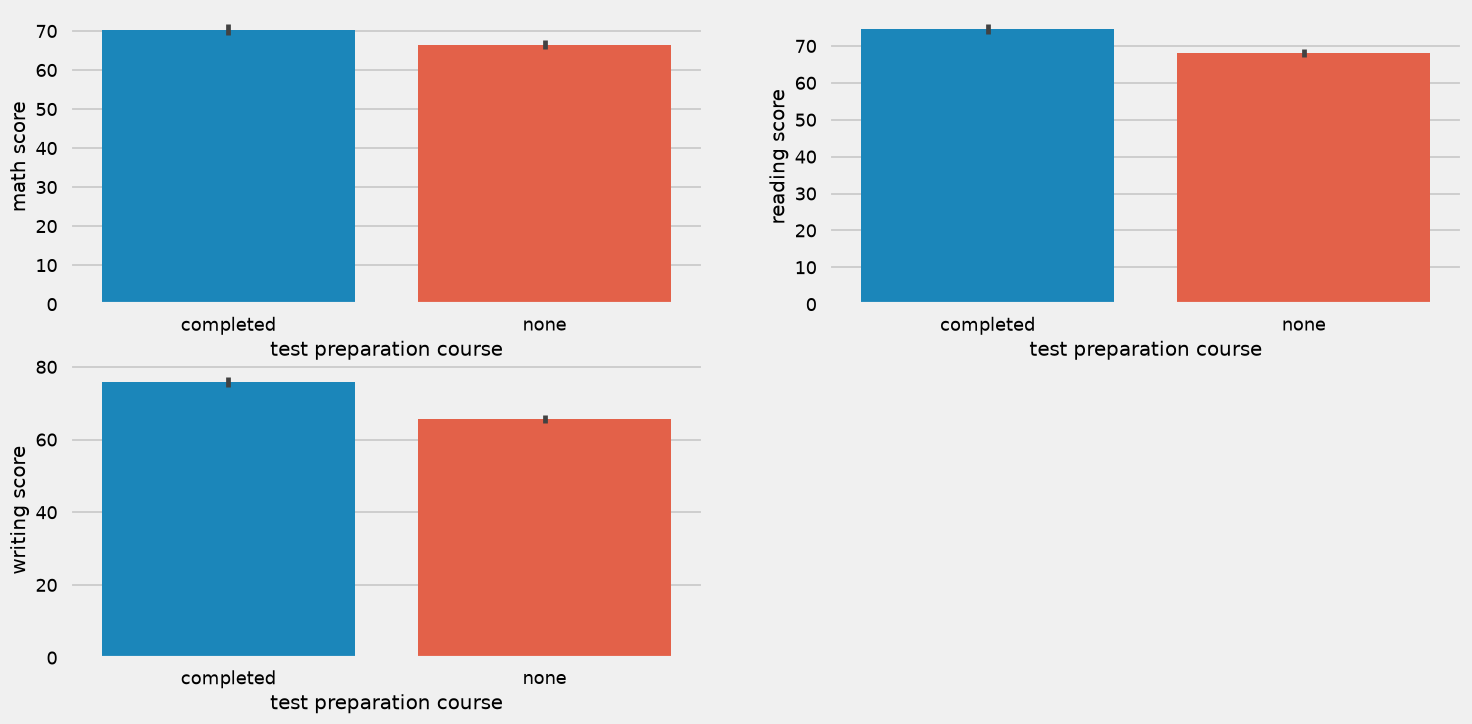

In [36]:
plt.figure(figsize=(16,8))
plt.subplot(2,2,1)
sns.barplot (x=df['test preparation course'], y=df['math score'], hue=df['test preparation course'])
plt.subplot(2,2,2)
sns.barplot (x=df['test preparation course'], y=df['reading score'], hue=df['test preparation course'])
plt.subplot(2,2,3)
sns.barplot (x=df['test preparation course'], y=df['writing score'], hue=df['test preparation course'])

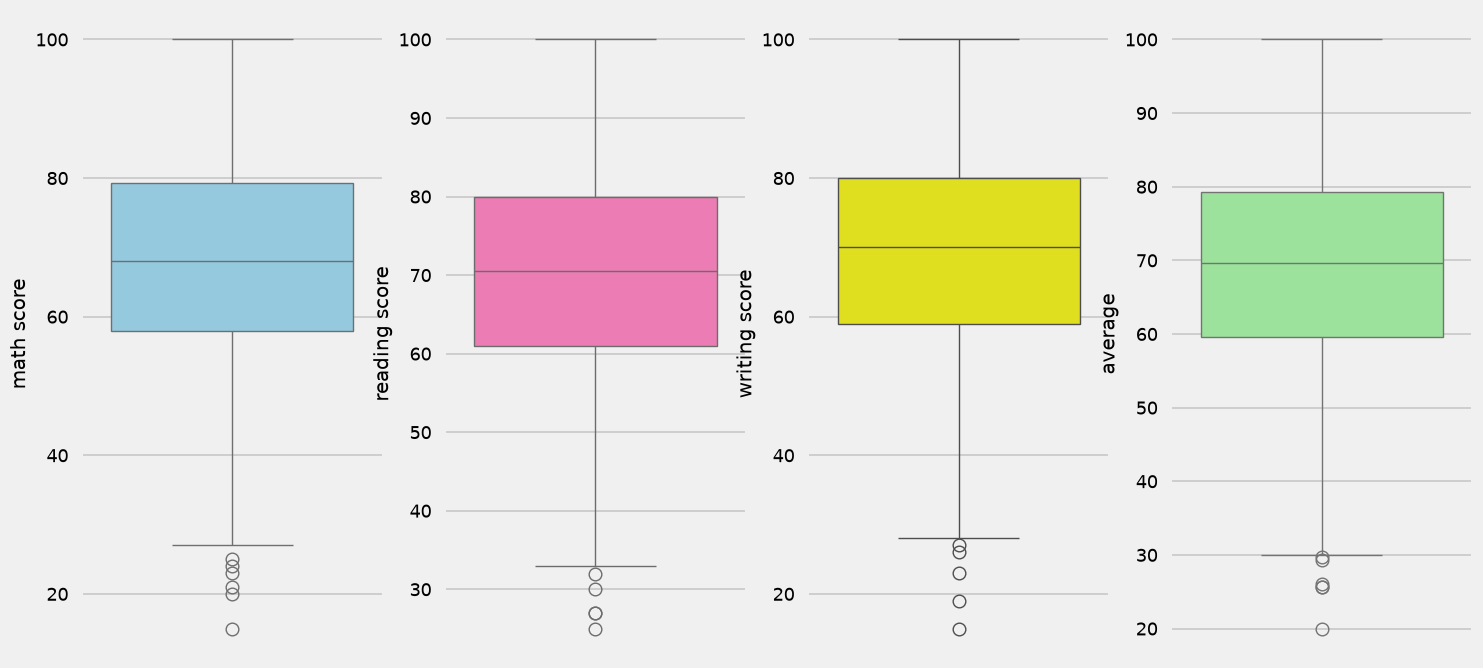

In [37]:
plt.subplots(1,4,figsize=(16,8))
plt.subplot(141)
sns.boxplot(df['math score'],color='skyblue')
plt.subplot(142)
sns.boxplot(df['reading score'],color='hotpink')
plt.subplot(143)
sns.boxplot(df['writing score'],color='yellow')
plt.subplot(144)
sns.boxplot(df['average'],color='lightgreen')
plt.show()

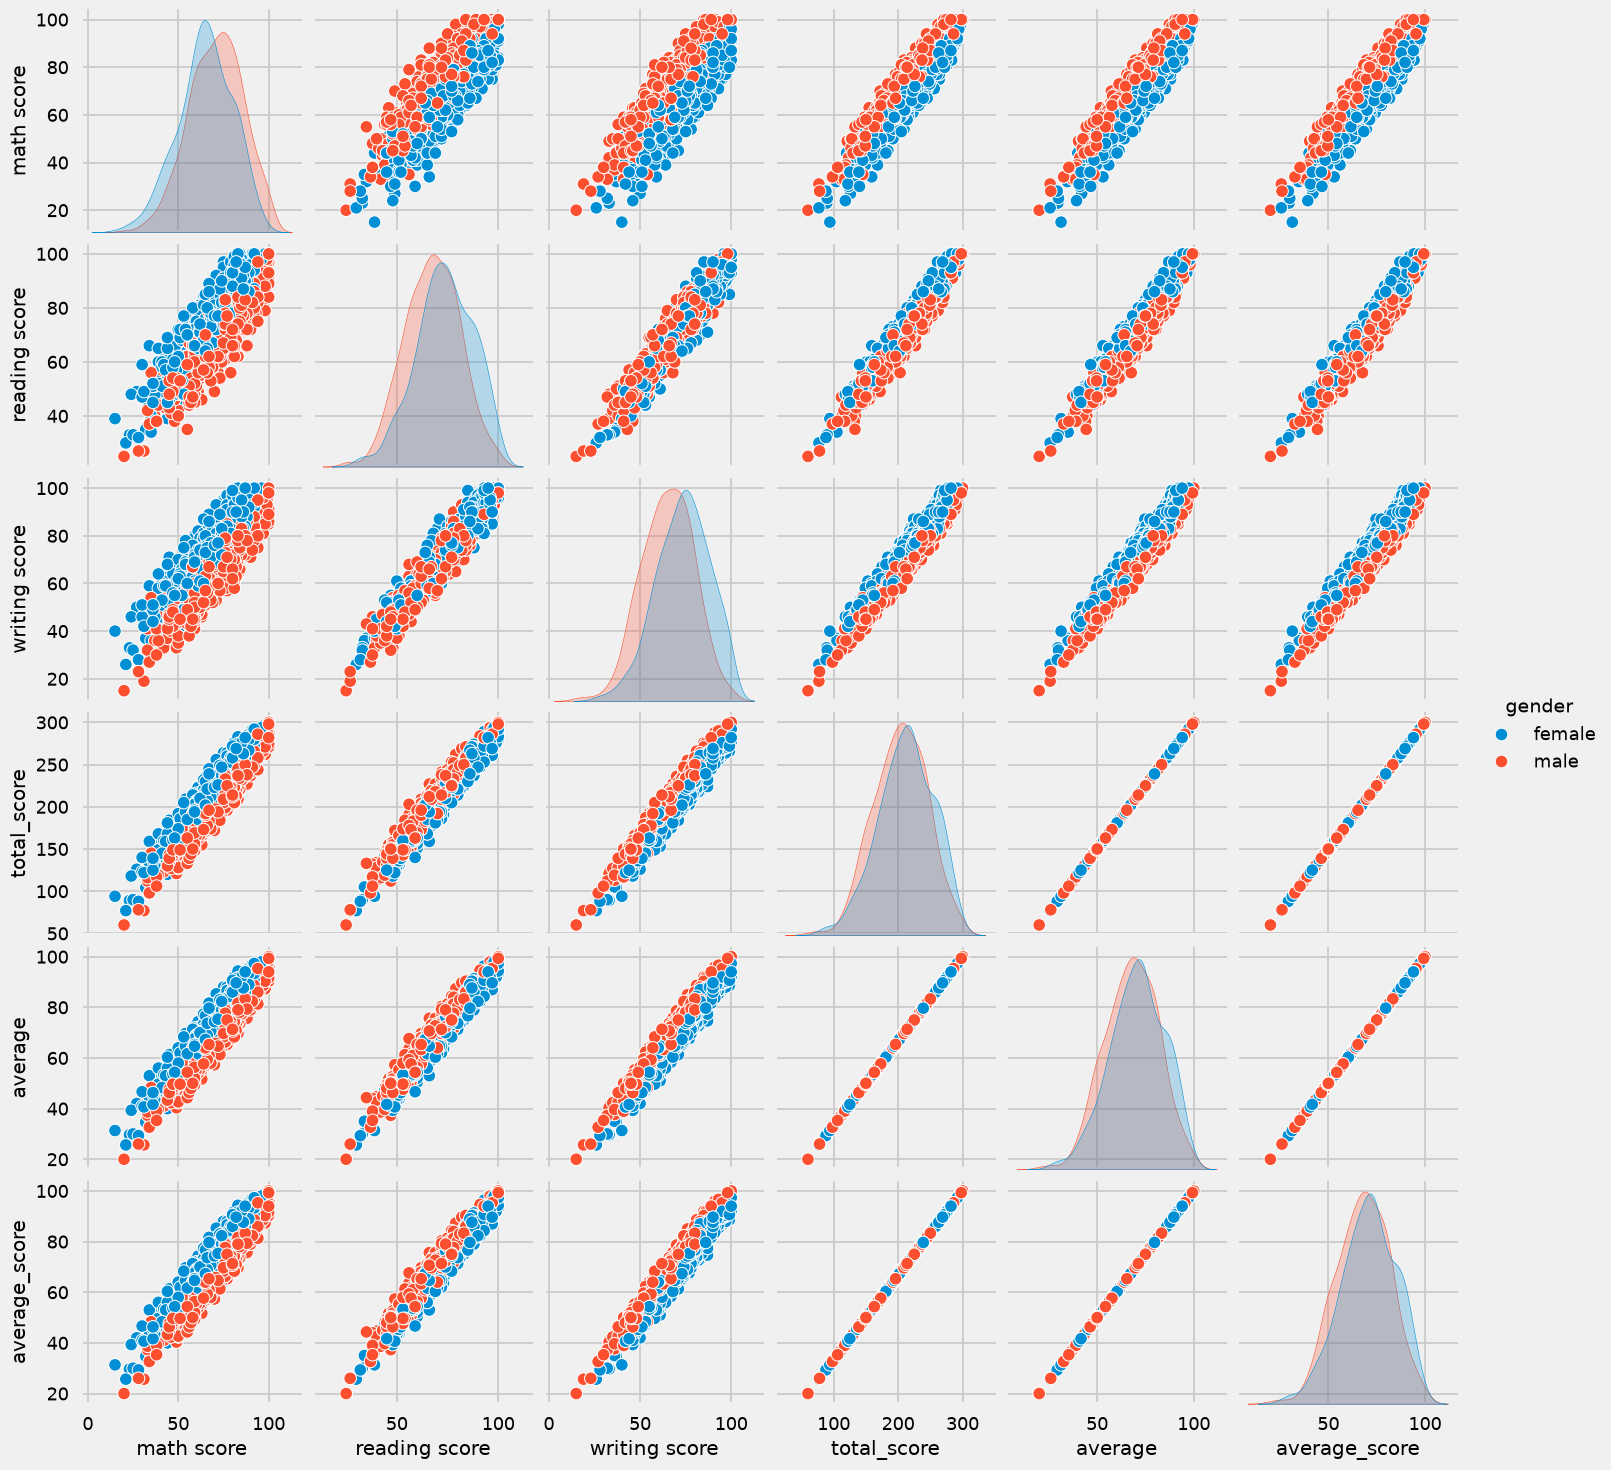

In [38]:
sns.pairplot(df,hue = 'gender')
plt.show()